In [1]:
import os
os.chdir(r"C:\Users\usuario\Desktop\Visao Computacional\Deteccao de Beija Flor")

import torch
from PIL import Image

from src.classification.dataset import eval_transform
from src.classification.predict import load_classifier
from src.common.paths import CROPS_DIR, WEIGHTS_DIR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, ckpt = load_classifier(WEIGHTS_DIR / "species_classifier_efficientnet_b0_v1.pt", device)

crop_path = next(CROPS_DIR.rglob("*41eb1fb7c15c48a680b631725c1ff868*"))
print(crop_path)
image = Image.open(crop_path).convert("RGB")

with torch.no_grad():
    x = eval_transform(ckpt["img_size"])(image).unsqueeze(0).to(device)
    probs = model(x).softmax(dim=1)[0]

top = probs.topk(2)
for p, i in zip(top.values.tolist(), top.indices.tolist()):
    print(f"{ckpt['classes'][i]}: {p:.1%}")

C:\Users\usuario\Desktop\Visao Computacional\Deteccao de Beija Flor\data\crops\test\Black-chinned_Hummingbird\nabirds_41eb1fb7c15c48a680b631725c1ff868.jpg
Costas_Hummingbird: 62.8%
Black-chinned_Hummingbird: 36.4%


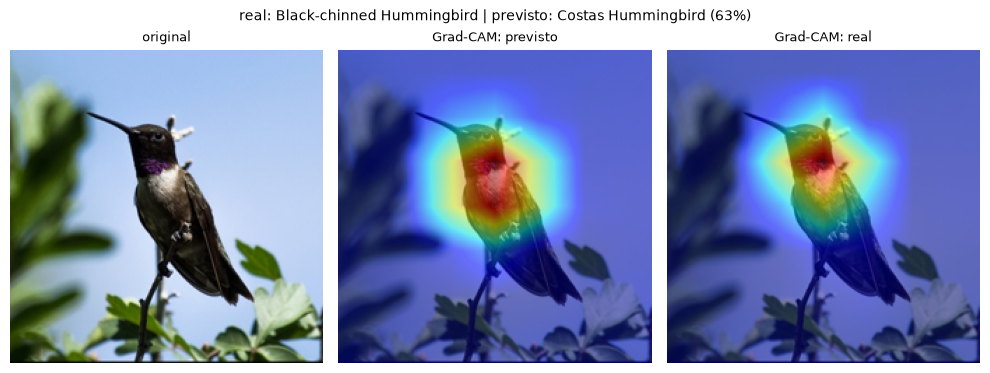

In [2]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "src").exists():
    root = root.parent
os.chdir(root)

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from src.classification.dataset import eval_transform
from src.classification.predict import load_classifier
from src.common.config import load_yaml
from src.common.paths import CROPS_DIR, WEIGHTS_DIR
from src.explainability.gradcam import GradCAM, overlay

cfg = load_yaml("classifier")
gcfg = load_yaml("gradcam")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
run_name = f"{cfg['name']}_{cfg['arch']}_{cfg['version']}"
model, ckpt = load_classifier(WEIGHTS_DIR / f"{run_name}.pt", device)
classes = ckpt["classes"]
gradcam = GradCAM(model, model.get_submodule(gcfg["target_layer"]))
size = cfg["img_size"]
transform = eval_transform(size)


def show(name: str) -> str:
    return name.replace("_", " ")


def explain(stem: str):
    matches = list((CROPS_DIR / gcfg["split"]).rglob(f"{stem}.*"))
    if not matches:
        raise FileNotFoundError(f"Recorte não encontrado em {CROPS_DIR / gcfg['split']}: {stem}")
    path = matches[0]
    target = classes.index(path.parent.name)

    pil = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)
    image = np.asarray(pil.resize((size, size))) / 255.0

    cam, probs = gradcam(tensor)
    pred = int(probs.argmax())
    cam_true, _ = gradcam(tensor, target)
    panels = [
        (image, "original"),
        (overlay(image, cam, gcfg["alpha"], gcfg["colormap"]), "Grad-CAM: previsto"),
        (overlay(image, cam_true, gcfg["alpha"], gcfg["colormap"]), "Grad-CAM: real"),
    ]
    title = f"real: {show(classes[target])} | previsto: {show(classes[pred])} ({probs[pred]:.0%})"
    return panels, title


panels, title = explain("nabirds_41eb1fb7c15c48a680b631725c1ff868")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))
for ax, (image, subtitle) in zip(axes, panels):
    ax.imshow(image)
    ax.set_title(subtitle, fontsize=9)
    ax.axis("off")
fig.suptitle(title, fontsize=10)
fig.tight_layout()
plt.show()